# Import Libraries and Loading Dataset

In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
import numpy as np
from scipy.stats import kurtosis, skew, norm


In [2]:
import os

path = "/content/Sleep_health_and_lifestyle_dataset.csv"
if not os.path.exists(path):
    path = "Sleep_health_and_lifestyle_dataset.csv"

df = pd.read_csv(path, keep_default_na=False)

In [3]:
df.shape

(374, 13)

In [4]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [6]:
df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


In [7]:
df["Sleep Disorder"].unique()

array(['None', 'Sleep Apnea', 'Insomnia'], dtype=object)

In [8]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


# Data Cleaning

Blood Pressure is split into systolic and diastolic to make for easier data handling and interpretation.

In [9]:
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True)

In [10]:
df['Systolic_BP']=pd.to_numeric(df['Systolic_BP'])
df['Diastolic_BP'] = pd.to_numeric(df['Diastolic_BP'])

In [11]:
df = df.drop(columns=['Person ID','Occupation', 'Blood Pressure'])

In [12]:
le=LabelEncoder()
for col in ['Gender', 'BMI Category']:
    df[col] = le.fit_transform(df[col])
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"{col} mapping:", mapping)

Gender mapping: {'Female': np.int64(0), 'Male': np.int64(1)}
BMI Category mapping: {'Normal': np.int64(0), 'Normal Weight': np.int64(1), 'Obese': np.int64(2), 'Overweight': np.int64(3)}


In [13]:
df['Sleep Disorder'] = df['Sleep Disorder'].replace({'None': 0, 'Insomnia': 1, 'Sleep Apnea': 1 })

/tmp/ipykernel_7914/2107190953.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Sleep Disorder'] = df['Sleep Disorder'].replace({'None': 0, 'Insomnia': 1, 'Sleep Apnea': 1 })


In [14]:
df.head(20)

,Gender,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,27,6.1,6,42,6,3,77,4200,0,126,83
1,1,28,6.2,6,60,8,0,75,10000,0,125,80
2,1,28,6.2,6,60,8,0,75,10000,0,125,80
3,1,28,5.9,4,30,8,2,85,3000,1,140,90
4,1,28,5.9,4,30,8,2,85,3000,1,140,90
5,1,28,5.9,4,30,8,2,85,3000,1,140,90
6,1,29,6.3,6,40,7,2,82,3500,1,140,90
7,1,29,7.8,7,75,6,0,70,8000,0,120,80
8,1,29,7.8,7,75,6,0,70,8000,0,120,80
9,1,29,7.8,7,75,6,0,70,8000,0,120,80


# Model Building & Evaluation

In [15]:
def descriptive_stats(series, name):
  """ Calculates the mean, (sample) variance, skewness and kurtosis"""
  mean = np.mean(series)
  variance = np.var(series, ddof=1)
  skewness = skew(series, bias=True)
  kurt = kurtosis(series, bias=True)

  print("Name: ", name)
  print(f"Mean: {mean:.3f}")
  print(f"Variance: {variance:.3f}")
  print(f"Skewness: {skewness:.3f}")
  print(f"Kurtosis: {kurt:.3f}")
  return mean, variance, skewness, kurt

In [16]:
def plot_hist_with_gaussian(series, title, bins=10, color = 'pink'):
  """ Plot PDF histogram and overlay with Gaussian distribution. """
  mean = np.mean(series)
  std = np.std(series, ddof = 0)

  x = np.linspace(series.min(), series.max(), 100)

  y = norm.pdf(x, mean, std)

  plt.hist(series, bins = bins, density = True, color =color, edgecolor='black')
  plt.plot(x, y, color = 'red', linewidth = 3)
  plt.title(f'{title} Histogram with Gaussian')
  plt.xlabel(title)
  plt.ylabel('Probability Density')
  plt.show()

In [17]:
def plot_cdf(series, title, color = 'blue'):
  """ Plot CDF """

  plt.figure(figsize = (8,4))
  plt.hist(series, bins = 10,  density=True, cumulative=True, color=color, edgecolor='black', alpha=0.6)
  plt.title(f" CDF of {title}")
  plt.xlabel(title)
  plt.ylabel("CDF")
  plt.grid(True)
  plt.show()

In [18]:
def plot_hist_bins(series, title, bin_list = [5, 10, 20], color = 'green'):
  """ Analysing effects of different bin widths """

  plt.figure(figsize=(10,4))
  for i, bins in enumerate(bin_list, 1):
    plt.subplot(1, len(bin_list), i)
    plt.hist(series, bins = bins, color=color, edgecolor='black')
    plt.title(f"{title} Histogram\nBins = {bins}")
    plt.xlabel(title)
    plt.ylabel('Frequency')
  plt.tight_layout()
  plt.show()

In [19]:
def correlation_analysis(df, c1, c2):
  """ Calculates the covariance and correlation. """
  correlation = df[c1].corr(df[c2])
  covariance = np.cov(df[c1], df[c2])[0,1]
  print(f"Covariance between {c1} and {c2}: {covariance:.3f}")
  print(f"Correlation coefficient between {c1} and {c2}: {correlation:.3f}")

  return correlation, covariance

In [20]:
def linear_regression(X, y, feature_name, target):
  """ Peform and plot linear regression, return correlation"""
  model = LinearRegression()
  model.fit(X, y)
  y_pred = model.predict(X)

  y_true = y.values.flatten()
  y_pred_flat = y_pred.flatten()

  correlation = np.corrcoef(y_true, y_pred_flat)[0,1]


  plt.figure(figsize =(10, 4))
  plt.scatter(X, y, color = 'green', label = 'Actual')
  plt.plot(X, y_pred, color ='red', label = 'Predicted')
  plt.title(f"{target} vs {feature_name}: Linear Regression")
  plt.xlabel(feature_name)
  plt.ylabel(target)
  plt.legend()

  plt.tight_layout()
  plt.show()

  print(f"Correlation between actual and predicted {target} from {feature_name}: {correlation:.3f}")
  return correlation



In [21]:
def analyse_gender(df, gender):
  """ Perform descriptive statistics, histogram, Gausssian and correlation analysis for each gender."""
  gender_mapping = {1: 'Male', 0: 'Female'}
  gender_label = gender_mapping[gender]

  subset = df[df['Gender']== gender]


  print(f" Analysis for {gender_label}: ")

  descriptive_stats(subset['Stress Level'], f"Stress Level ({gender_label})")
  descriptive_stats(subset['Sleep Duration'], f"Sleep Duration ({gender_label})")
  descriptive_stats(subset['Physical Activity Level'], f"Physical Activity Level ({gender_label})")

  plot_hist_with_gaussian(subset['Stress Level'], f" Stress Level ({gender_label})")
  plot_hist_with_gaussian(subset['Sleep Duration'], f" Sleep Duration ({gender_label})")
  plot_hist_with_gaussian(subset['Physical Activity Level'], f" Physical Activity Level ({gender_label})")

  plot_hist_bins(subset['Stress Level'], f"Stress Level ({gender_label})", bin_list =[5, 10, 20])
  plot_hist_bins(subset['Sleep Duration'], f"Sleep Duration ({gender_label})", bin_list = [5, 10, 20])
  plot_hist_bins(subset['Physical Activity Level'], f"Physical Activity Level ({gender_label})", [5, 10, 20])

  plot_cdf(subset['Stress Level'], f" Stress Level ({gender_label})")
  plot_cdf(subset['Sleep Duration'], f" Sleep Duration ({gender_label})")
  plot_cdf(subset['Physical Activity Level'], f" Physical Activity Level ({gender_label})")

  correlation_analysis(subset, 'Stress Level', 'Sleep Duration')
  correlation_analysis(subset, 'Physical Activity Level', 'Sleep Duration')
  correlation_analysis(subset, 'Physical Activity Level', 'Stress Level')

#Dataset Analysis
#using constructed functions

plot cdf
plot hist bins

Name:  Stress Level
Mean: 5.385
Variance: 3.149
Skewness: 0.154
Kurtosis: -1.326

Name:  Sleep Duration
Mean: 7.132
Variance: 0.633
Skewness: 0.037
Kurtosis: -1.285

Name:  Physical Activity Level
Mean: 59.171
Variance: 433.922
Skewness: 0.074
Kurtosis: -1.265



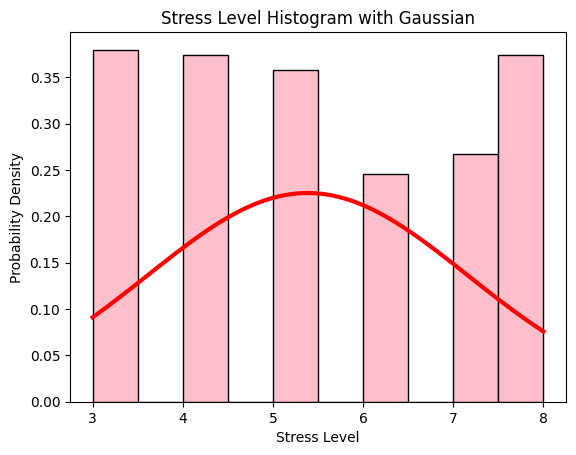

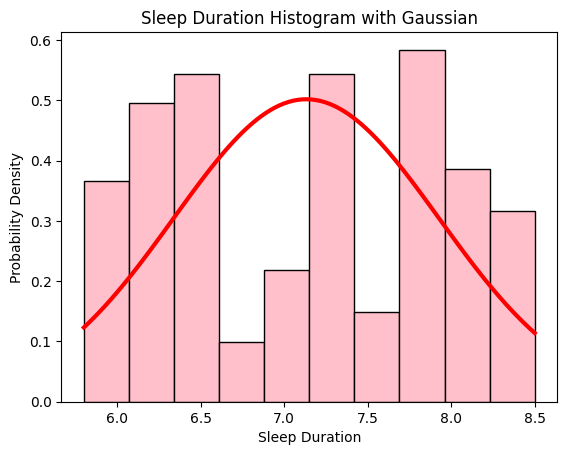

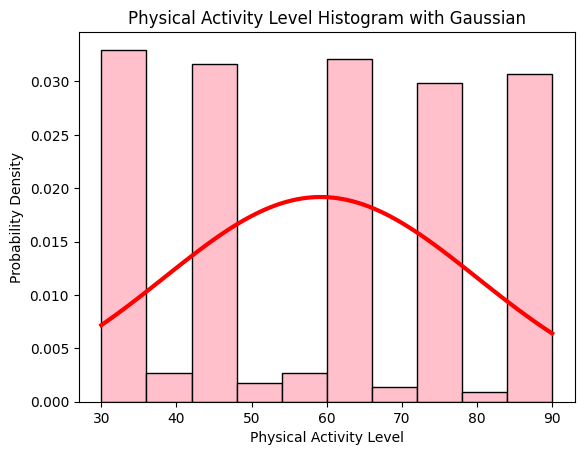


Covariance between Stress Level and Sleep Duration: -1.145
Correlation coefficient between Stress Level and Sleep Duration: -0.811

Covariance between Physical Activity Level and Sleep Duration: 3.520
Correlation coefficient between Physical Activity Level and Sleep Duration: 0.212

Covariance between Physical Activity Level and Stress Level: -1.262
Correlation coefficient between Physical Activity Level and Stress Level: -0.034



In [22]:
descriptive_stats(df['Stress Level'], "Stress Level")
print()
descriptive_stats(df['Sleep Duration'], 'Sleep Duration')
print()
descriptive_stats(df['Physical Activity Level'], "Physical Activity Level")
print()


plot_hist_with_gaussian(df['Stress Level'], "Stress Level")
print()
plot_hist_with_gaussian(df['Sleep Duration'], 'Sleep Duration')
print()
plot_hist_with_gaussian(df['Physical Activity Level'], "Physical Activity Level")
print()


correlation_analysis(df, 'Stress Level', "Sleep Duration")
print()
correlation_analysis(df, 'Physical Activity Level', 'Sleep Duration')
print()
correlation_analysis(df, 'Physical Activity Level', "Stress Level")
print()


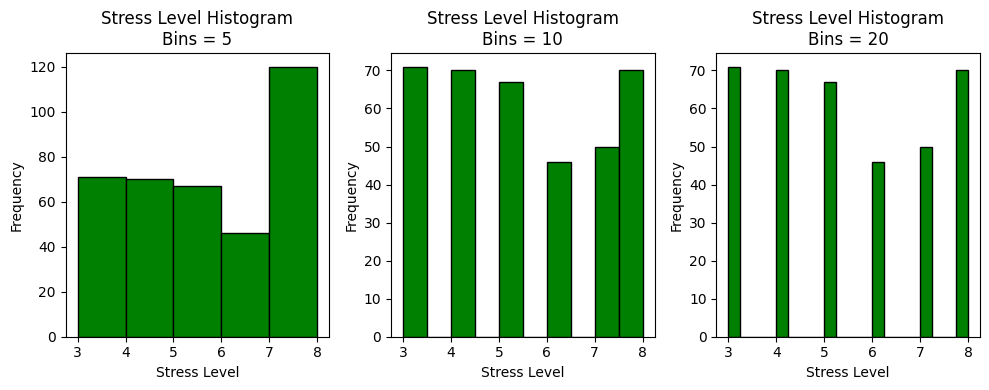

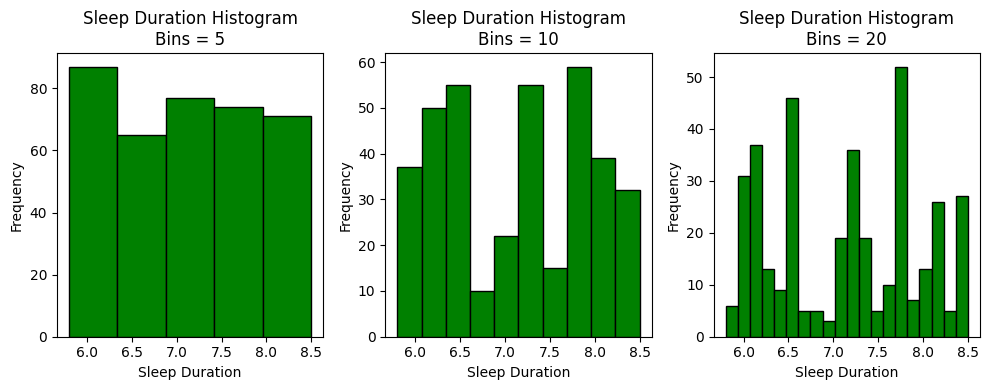

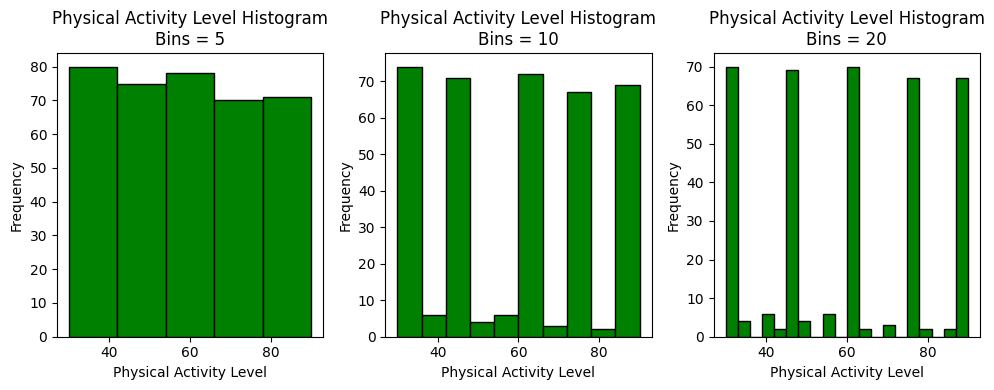

In [23]:
plot_hist_bins(df['Stress Level'], "Stress Level", bin_list = [5, 10,20])
plot_hist_bins(df['Sleep Duration'], "Sleep Duration", bin_list = [5, 10,20])
plot_hist_bins(df['Physical Activity Level'], "Physical Activity Level", bin_list = [5, 10,20])

Effect of changing bin size:

Reducing bin size: the histograms appear to be more smoother and it is easier to identify the overall trend and pattern. However, minute details may not be captured and the trend may be oversimplified

When increasing bin size: the histogram is more detailed as it captures small details and minor changes. This may make the histogram look more noisy, and make it harder to identify the overall trend and pattern.

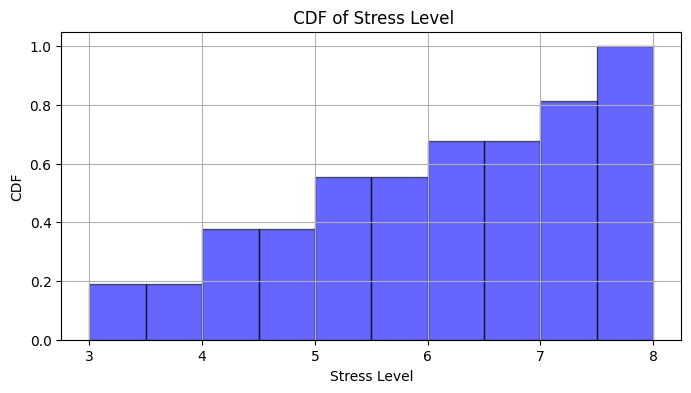

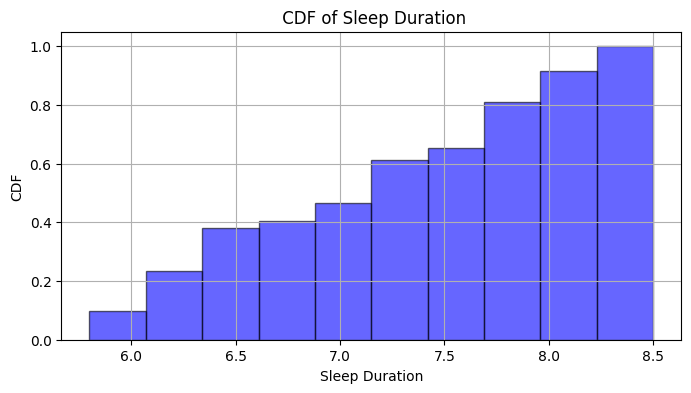

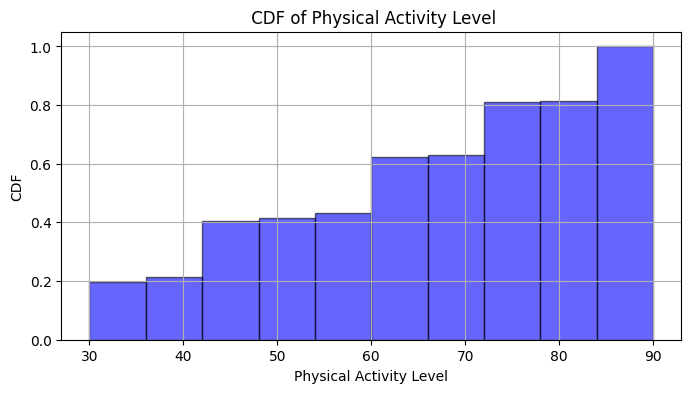

In [24]:
plot_cdf(df['Stress Level'], "Stress Level")
plot_cdf(df['Sleep Duration'], "Sleep Duration")
plot_cdf(df['Physical Activity Level'], "Physical Activity Level")

#Gender Wise Analysis

Male

 Analysis for Male: 
Name:  Stress Level (Male)
Mean: 6.079
Variance: 1.690
Skewness: 0.013
Kurtosis: -0.879
Name:  Sleep Duration (Male)
Mean: 7.037
Variance: 0.481
Skewness: -0.275
Kurtosis: -1.517
Name:  Physical Activity Level (Male)
Mean: 59.201
Variance: 428.576
Skewness: 0.073
Kurtosis: -1.248


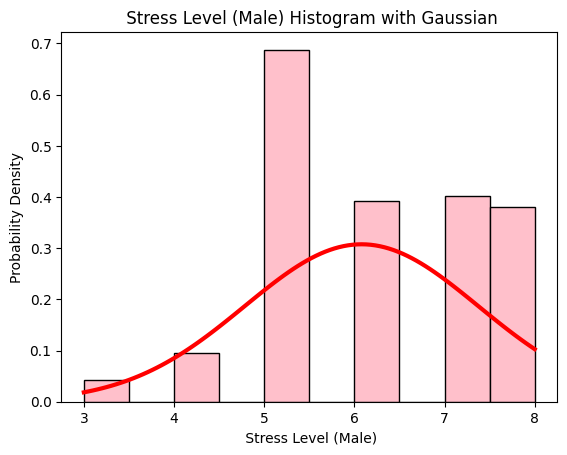

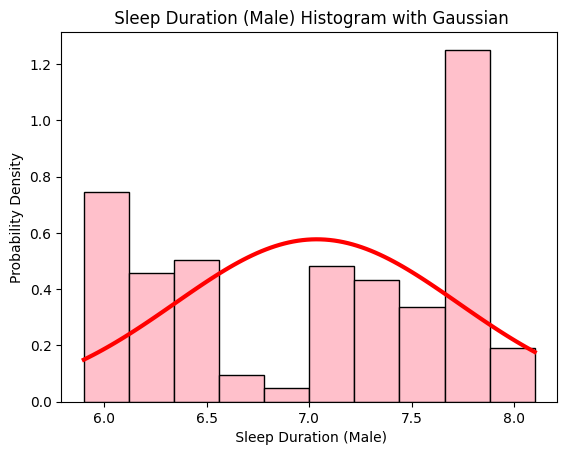

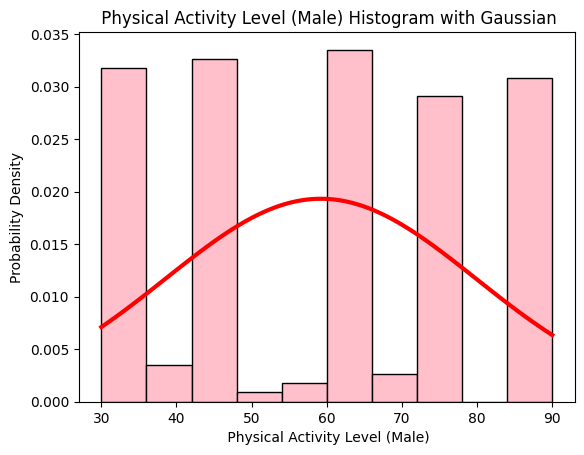

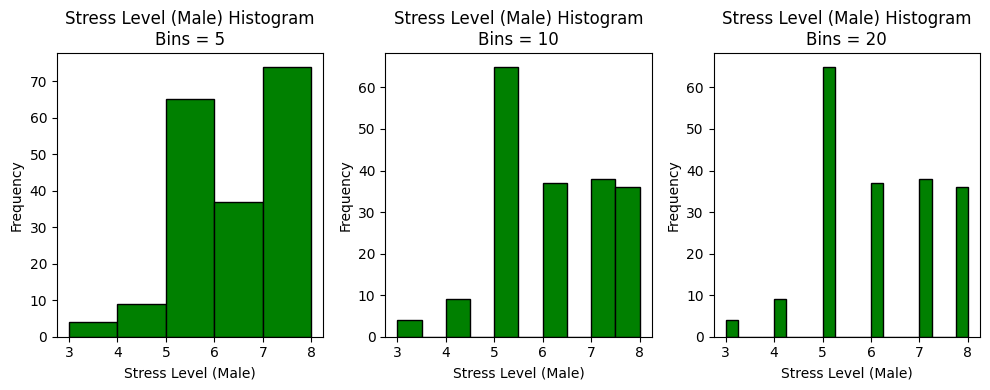

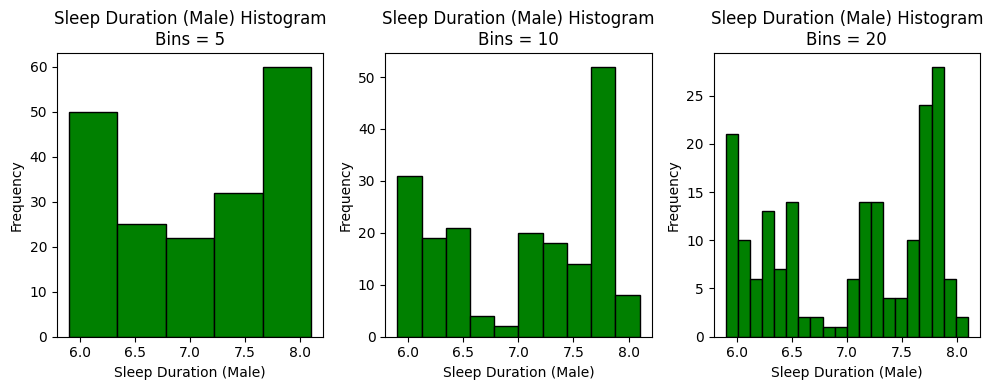

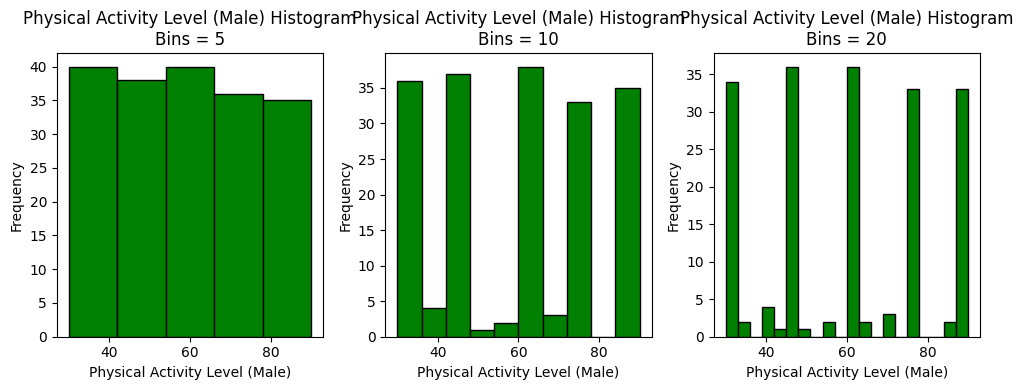

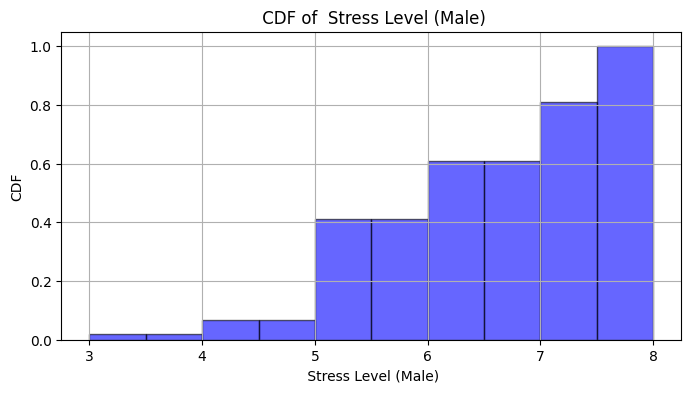

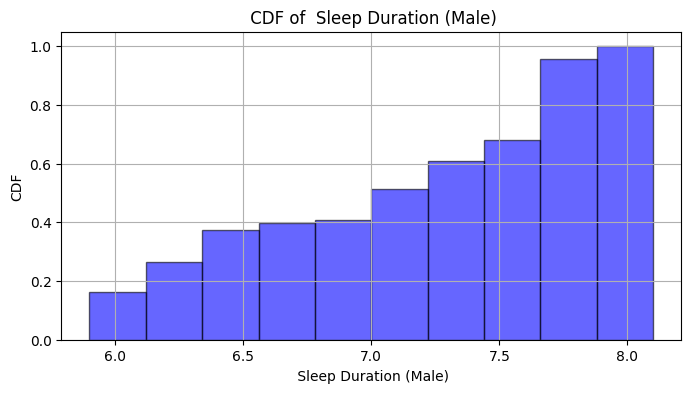

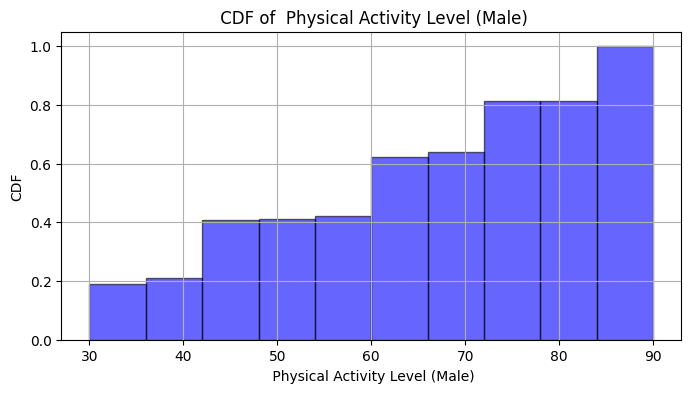

Covariance between Stress Level and Sleep Duration: -0.743
Correlation coefficient between Stress Level and Sleep Duration: -0.824
Covariance between Physical Activity Level and Sleep Duration: 13.364
Correlation coefficient between Physical Activity Level and Sleep Duration: 0.931
Covariance between Physical Activity Level and Stress Level: -19.766
Correlation coefficient between Physical Activity Level and Stress Level: -0.734


In [25]:
analyse_gender(df, gender=1)

Female

 Analysis for Female: 
Name:  Stress Level (Female)
Mean: 4.676
Variance: 3.655
Skewness: 0.847
Kurtosis: -0.926
Name:  Sleep Duration (Female)
Mean: 7.230
Variance: 0.773
Skewness: 0.067
Kurtosis: -1.460
Name:  Physical Activity Level (Female)
Mean: 59.141
Variance: 441.741
Skewness: 0.075
Kurtosis: -1.282


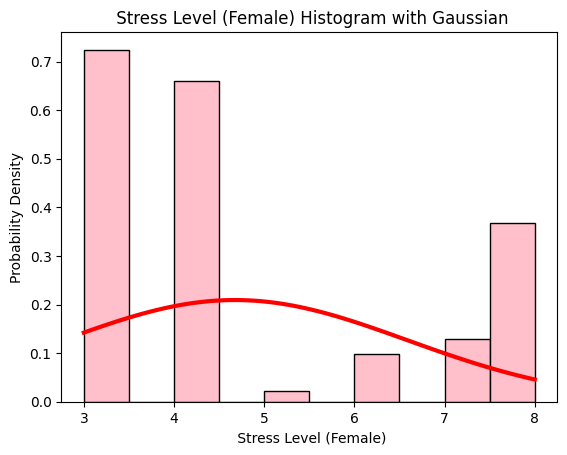

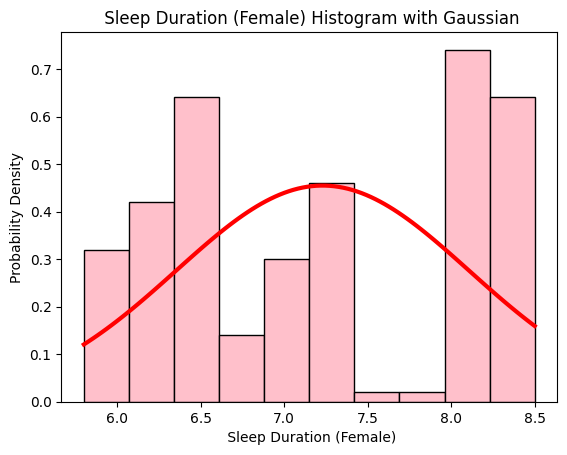

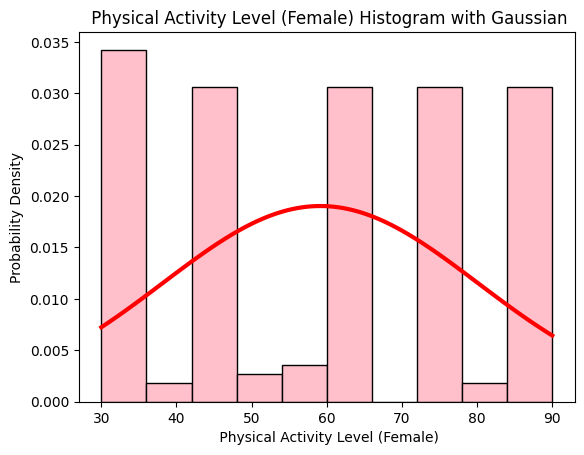

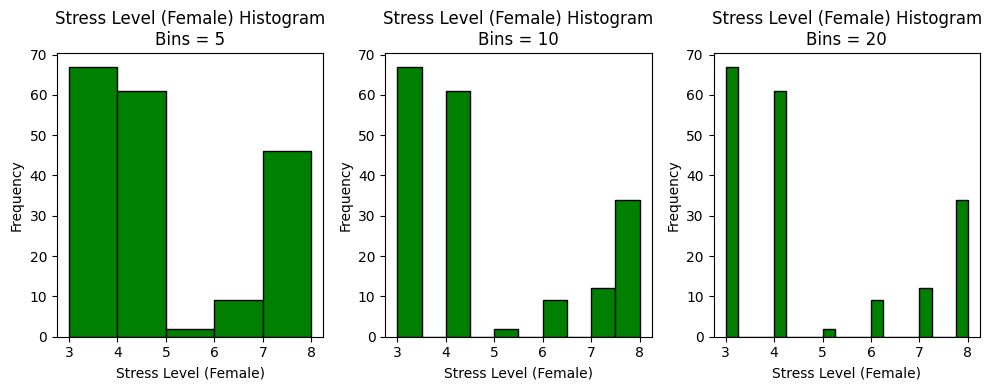

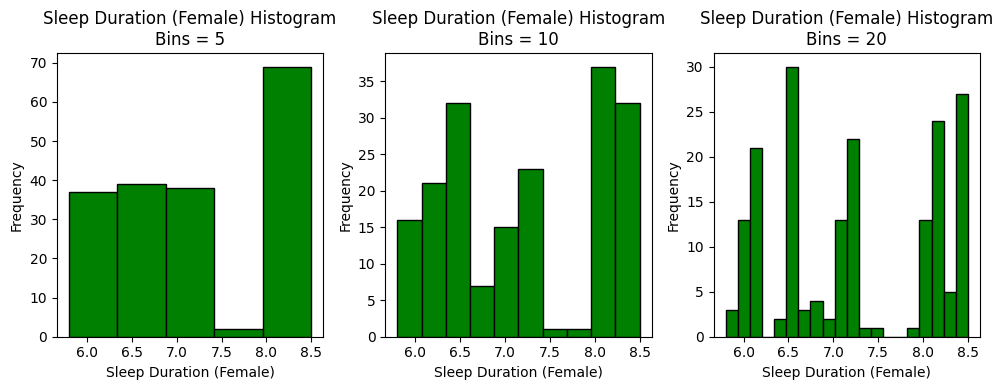

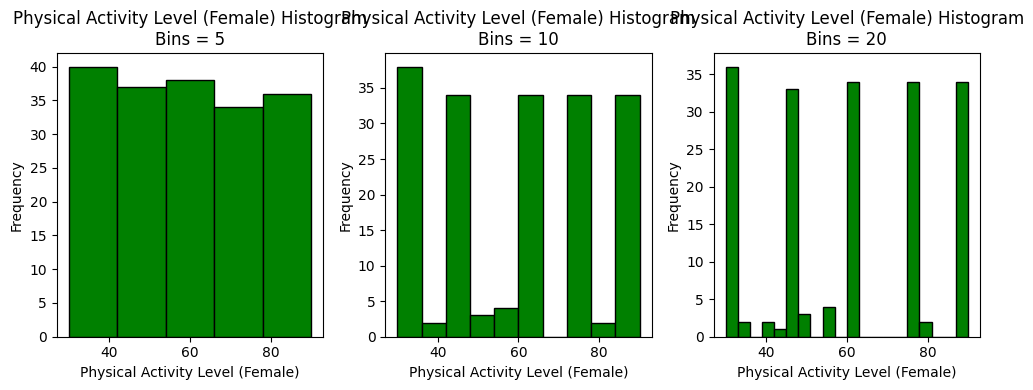

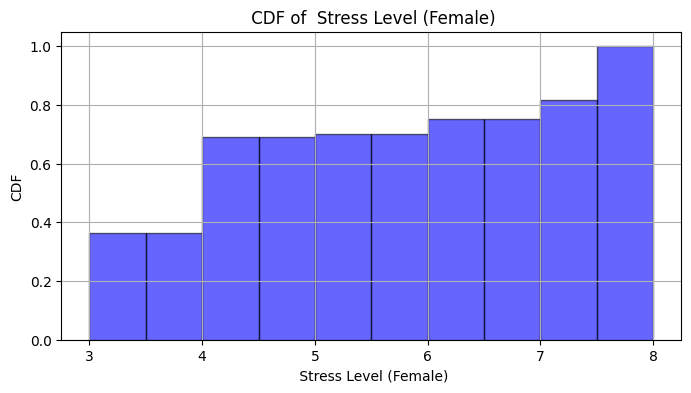

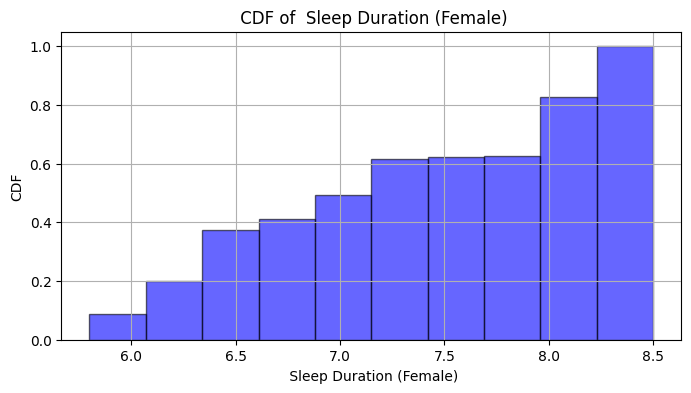

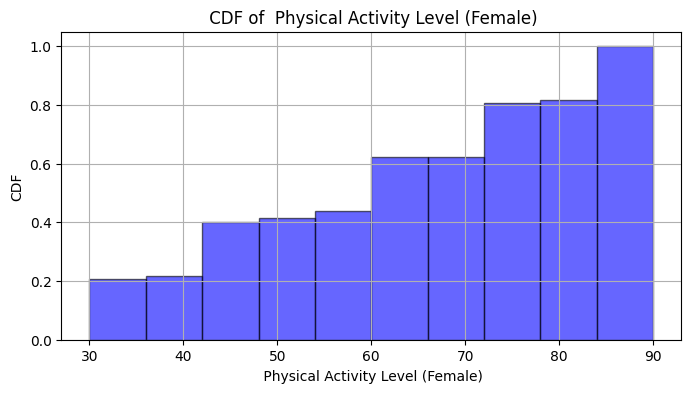

Covariance between Stress Level and Sleep Duration: -1.425
Correlation coefficient between Stress Level and Sleep Duration: -0.847
Covariance between Physical Activity Level and Sleep Duration: -6.514
Correlation coefficient between Physical Activity Level and Sleep Duration: -0.352
Covariance between Physical Activity Level and Stress Level: 17.595
Correlation coefficient between Physical Activity Level and Stress Level: 0.438


In [26]:
analyse_gender(df, gender=0)

#Linear Regression

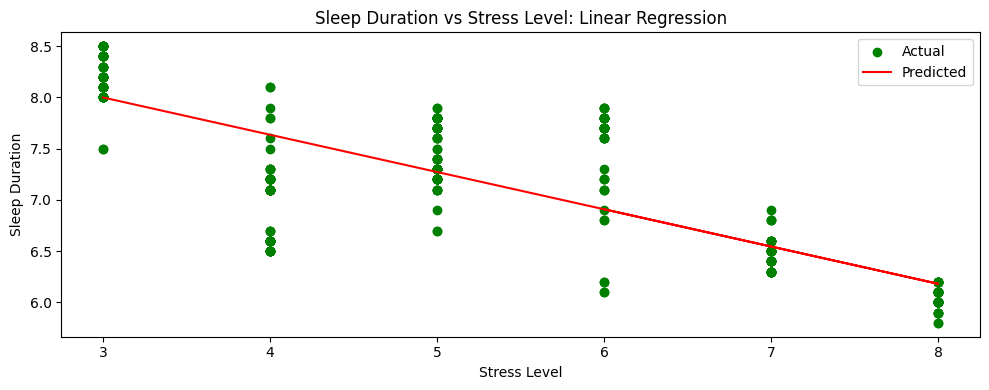

Correlation between actual and predicted Sleep Duration from Stress Level: 0.811


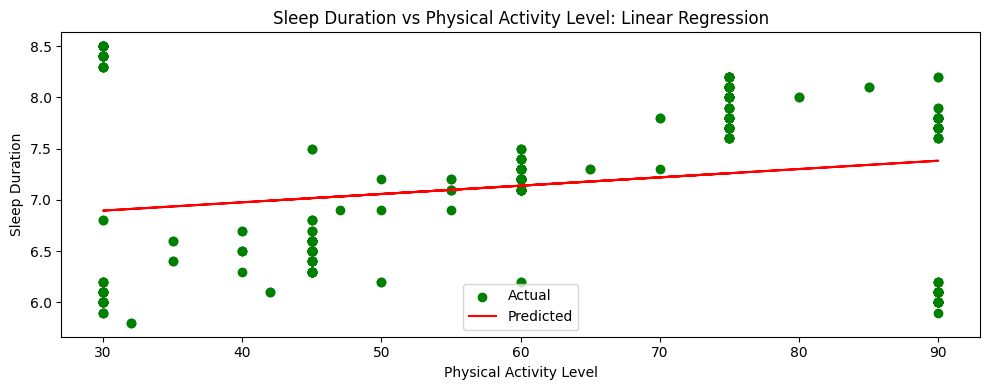

Correlation between actual and predicted Sleep Duration from Physical Activity Level: 0.212
Decision Tree Evaluation
Accuracy: 0.893

Classification Report: 
              precision    recall  f1-score   support

           0       0.89      0.93      0.91        43
           1       0.90      0.84      0.87        32

    accuracy                           0.89        75
   macro avg       0.89      0.89      0.89        75
weighted avg       0.89      0.89      0.89        75



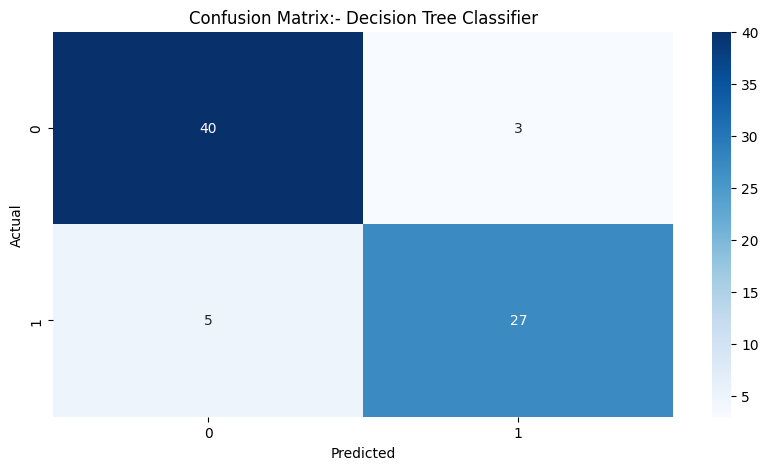

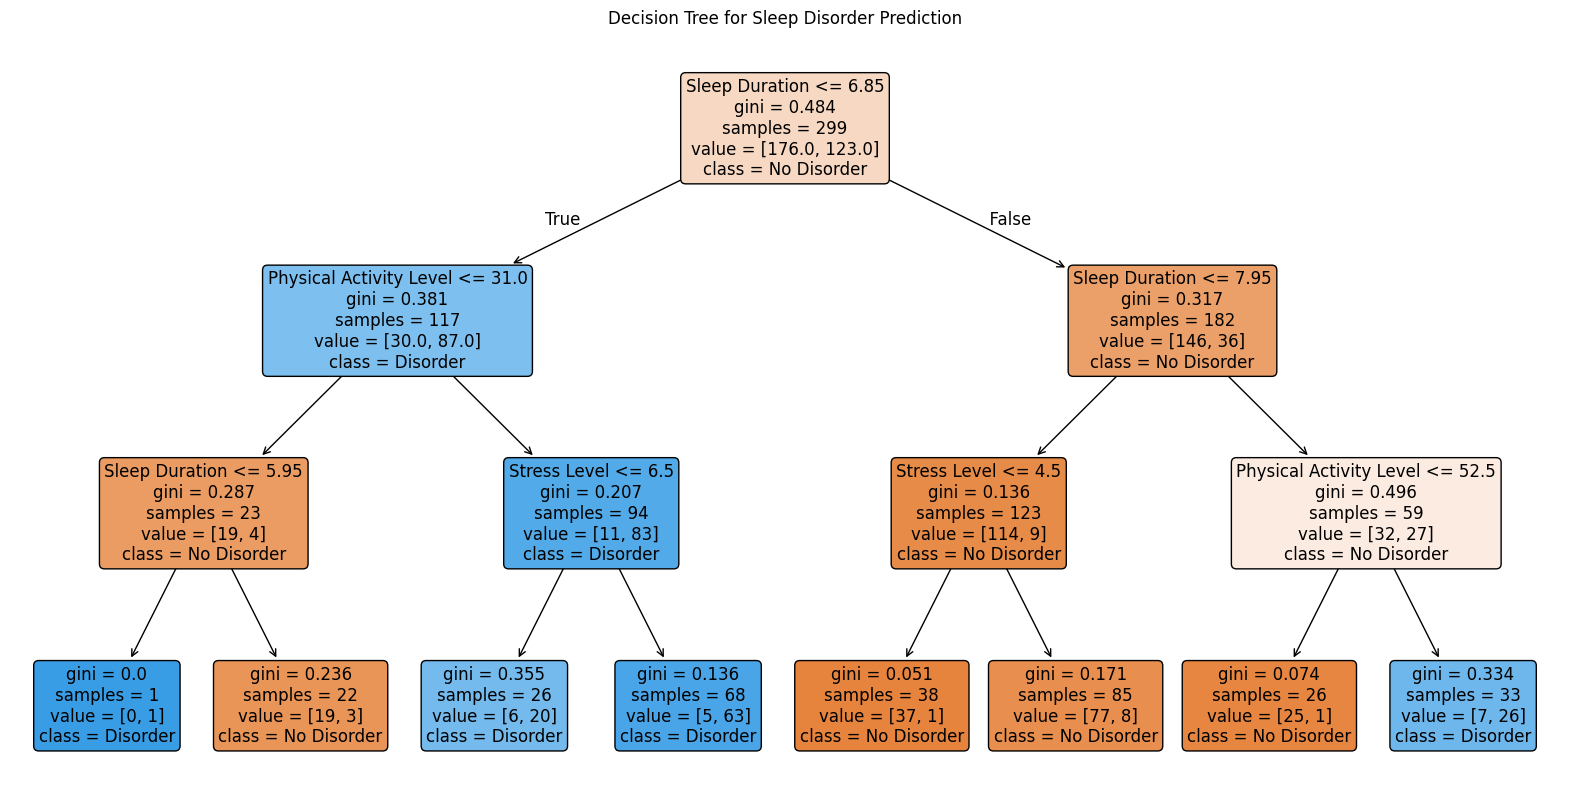

In [27]:
linear_regression(df[['Stress Level']], df[['Sleep Duration']], 'Stress Level', 'Sleep Duration')
linear_regression(df[['Physical Activity Level']], df[['Sleep Duration']], 'Physical Activity Level', 'Sleep Duration')

X = df[['Sleep Duration', 'Stress Level', 'Physical Activity Level']]
y = df['Sleep Disorder']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

dt_model = DecisionTreeClassifier(max_depth=3, random_state = 14)
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)

print("Decision Tree Evaluation")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print("Classification Report: ")
print(classification_report(y_test, y_pred))

plt.figure(figsize = (10, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt= 'd', cmap = 'Blues')
plt.title('Confusion Matrix:- Decision Tree Classifier')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

from sklearn import tree

plt.figure(figsize = (20, 10))
tree.plot_tree(dt_model, feature_names = ['Sleep Duration', 'Stress Level', 'Physical Activity Level'],
               class_names = ['No Disorder', 'Disorder'], filled = True, rounded = True, fontsize = 12)
plt.title("Decision Tree for Sleep Disorder Prediction")
plt.show()